Задача: построить модель бин. классификации, чтобы определить, купит ли пользователь хотя бы что-то за целевой месяц

In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import date, timedelta
from typing import Optional

from lightgbm import LGBMClassifier
from pathlib import Path

In [2]:
data = pl.read_parquet("data/train.parquet")
data.head()

event_date,user_id,search,cat,has_search_to_cart,has_search_to_ord,has_cat_to_cart,has_cat_to_ord,search_to_cart,search_to_ord,cat_to_cart,cat_to_ord,gmv_search,gmv_cat,to_cart,to_ord,gmv,searches
date,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,i64,i64,f64,i64
2025-06-16,2,1,0,0,0,0,0,0,0,0,0,0.0,0.0,0,0,0.0,2
2025-06-22,2,1,0,1,0,0,0,1,0,0,0,0.0,0.0,1,0,0.0,1
2025-08-08,2,1,0,0,0,0,0,0,0,0,0,0.0,0.0,0,0,0.0,1
2025-08-18,2,1,0,1,0,0,0,1,0,0,0,0.0,0.0,1,0,0.0,1
2025-08-23,2,1,0,0,0,0,0,0,0,0,0,0.0,0.0,0,0,0.0,1


In [3]:
# keep extra features for homework
DEFAULT_AGGS = ["sum", "max", "std", "mean"]
DEFAULT_VALUE_COLS = ["gmv", "searches"]

# and a place to save our stuff
FEATURES_DIR = "data/v2/features"

# and choose a simple path for now
N_FOLDS = 4

# mind your RAM capabilities
# in case of really low-RAM machines mind that data is sorted by user (and by event_date later)
BATCH_SIZE = 50_000

DEFAULT_WINDOWS = [
    # Название, Левая граница (t - X), Правая граница (t - Y)
    ("7d",     6,   0),   # [t-6,  t-0]  -> первые 7 дней (включая anchor)
    ("14d",    13,  7),   # [t-13, t-7]  -> следующие 7 дней (всего прошло 14 дней)
    ("30d",    29,  14),  # [t-29, t-14] -> блок в 16 дней (закрывает первый месяц)
    ("60d",    59,  30),  # [t-59, t-30] -> блок в 30 дней (второй месяц)
    ("90d",    89,  60),  # [t-89, t-60] -> блок в 30 дней (третий месяц)
    ("120d",   119, 90),  # [t-119, t-90]-> новый блок в 30 дней (четвертый месяц, до 120 дней)
]

output_dir = Path(FEATURES_DIR)
output_dir.mkdir(parents=True, exist_ok=True)

In [4]:
# Build key anchor dates for time-CV windows
def generate_cv_anchor_dates(
    data: pl.DataFrame,
    prediction_horizon_days: int = 30,
    stride_days: int = 14,
    min_history_days: int = 90,
    n_folds: Optional[int] = None,
) -> list[date]:
   
    min_date = data["event_date"].min()
    max_date = data["event_date"].max()

    latest_anchor = max_date - timedelta(days = prediction_horizon_days)
    earliest_anchor = min_date + timedelta(days = min_history_days - 1)

    # sanity check
    if latest_anchor < earliest_anchor:
        raise ValueError(
            f"Not enough data: need >={min_history_days + prediction_horizon_days - 1} days, "
            f"got {(max_date - min_date).days}."
        )

    n_steps = (latest_anchor - earliest_anchor).days // stride_days
    all_anchors = [latest_anchor - timedelta(days=i * stride_days) for i in range(n_steps + 1)]
    all_anchors = sorted(all_anchors)

    if n_folds is not None:
        if n_folds <= 0:
            raise ValueError("n_folds must be a positive integer.")
        return all_anchors[-n_folds:]
    
    return all_anchors

In [5]:
# helper feature recepies
# BYOF yet consider a tokenizer path instead :)
def _window_agg_exprs(
    anchor_val: date,
    windows: list[tuple[str, int, int]],
    value_cols: list[str],
    aggs: list[str],
) -> list[pl.Expr]:
    exprs = []
    for w_name, start_off, end_off in windows:
        w_start = anchor_val - timedelta(days = start_off)
        w_end = anchor_val - timedelta(days = end_off)
        mask = pl.col("event_date").is_between(w_start, w_end)

        for col in value_cols:
            for agg in aggs:
                if agg == "sum":
                    if col == "searches":
                        # Используем 0 вместо 0.0 и принудительно кастим в Int32
                        e = pl.when(mask).then(pl.col(col)).otherwise(0).sum().cast(pl.Int32)
                    else:
                        # Для gmv и остальных используем Float32
                        e = pl.when(mask).then(pl.col(col)).otherwise(0.0).sum().cast(pl.Float32)
                elif agg == "max":
                    if col == "searches":
                        e = pl.when(mask).then(pl.col(col)).otherwise(None).max().cast(pl.Int32)
                    else:
                        e = pl.when(mask).then(pl.col(col)).otherwise(None).max().cast(pl.Float32)
                elif agg == "std":
                    e = pl.when(mask).then(pl.col(col)).otherwise(None).std().cast(pl.Float32)
                elif agg == "mean":
                    e = pl.when(mask).then(pl.col(col)).otherwise(None).mean().cast(pl.Float32)
                elif agg == "count":
                    e = pl.when(mask).then(1).otherwise(0).sum().cast(pl.Int32)
                else:
                    raise ValueError(f"Unknown agg: {agg}")
                exprs.append(e.alias(f"{col}_{agg}_{w_name}"))
    return exprs

In [6]:
anchors_30d = generate_cv_anchor_dates(data=data, stride_days=30)

In [7]:
def generate_features(
    data: pl.DataFrame,
    anchor_dates: list[date],
    user_ids: Optional[list[int]] = None,
    value_cols: list[str] = DEFAULT_VALUE_COLS,
    windows: list[tuple[str, int, int]] = DEFAULT_WINDOWS,
    aggs: list[str] = DEFAULT_AGGS,
) -> pl.DataFrame:
    if user_ids is None:
        user_ids_series = data["user_id"].unique().sort().cast(pl.Int32)
    else:
        user_ids_series = pl.Series("user_id", user_ids, dtype=pl.Int32)

    max_back = max(w[1] for w in windows)
    min_anchor, max_anchor = min(anchor_dates), max(anchor_dates)

    # Filter once; keep only columns actually needed by the aggregations.
    needed_cols = ["user_id", "event_date"] + [c for c in value_cols if c not in ("user_id", "event_date")]
    data_f = (
        data
        .select(needed_cols)
        .filter(
            pl.col("user_id").is_in(user_ids_series.implode())
            & pl.col("event_date").is_between(
                min_anchor - timedelta(days=max_back),
                max_anchor,
            )
        )
    )

    # Build the full user/anchor index exactly as before, but use the already
    # materialized user series rather than a Python set.
    index_df = (
        pl.DataFrame({"anchor_date": anchor_dates}, schema={"anchor_date": pl.Date})
        .join(
            pl.DataFrame({"user_id": user_ids_series}, schema={"user_id": pl.Int32}),
            how="cross",
        )
    )

    parts = []
    for a in anchor_dates:
        ad = data_f.filter(pl.col("event_date") >= a - timedelta(days=max_back))
        if len(ad) > 0:
            features = (
                ad.group_by("user_id")
                .agg(_window_agg_exprs(a, windows, value_cols, aggs))
                .with_columns(anchor_date=pl.lit(a, dtype=pl.Date))
                .with_columns(pl.col("user_id").cast(pl.Int32))
            )
            parts.append(features)
        del ad

    if parts:
        features_df = pl.concat(parts, how="vertical")
        del parts
    else:
        features_df = pl.DataFrame(schema={"user_id": pl.Int32, "anchor_date": pl.Date})

    result = index_df.join(features_df, on=["anchor_date", "user_id"], how="left")

    feature_cols = [c for c in result.columns if c not in ["anchor_date", "user_id"]]
    # Keep the original fill semantics, while explicitly using Float32 to avoid
    # accidental upcasting.
    result = result.with_columns(
        [pl.col(c).fill_null(0.0).cast(pl.Float32) for c in feature_cols]
    )

    del data_f, features_df, index_df
    return result


In [8]:
def generate_targets(
    data: pl.DataFrame,
    anchor_dates: list[date],
    user_ids: Optional[list[int]] = None,
    horizon_days: int = 30,
    target_col: str = "gmv",
) -> pl.DataFrame:
    if user_ids is None:
        user_ids_series = data["user_id"].unique().cast(pl.Int32).sort()
    else:
        user_ids_series = pl.Series("user_id", user_ids, dtype=pl.Int32)

    index_df = (
        pl.DataFrame({"anchor_date": anchor_dates}, schema={"anchor_date": pl.Date})
        .join(
            pl.DataFrame({"user_id": user_ids_series}, schema={"user_id": pl.Int32}),
            how="cross",
        )
    )

    # Only the columns required for target construction are retained.
    target_data = data.select(["user_id", "event_date", target_col])

    parts = []
    for a in anchor_dates:
        t_start = a + timedelta(days=1)
        t_end = a + timedelta(days=horizon_days)
        tgt = (
            target_data
            .filter(pl.col("event_date").is_between(t_start, t_end))
            .group_by("user_id")
            .agg(pl.col(target_col).sum().cast(pl.Float32).alias("target"))
            .with_columns(anchor_date=pl.lit(a, dtype=pl.Date))
        )
        parts.append(tgt)

    if parts:
        tgt_df = pl.concat(parts, how="vertical")
        del parts
    else:
        tgt_df = pl.DataFrame(
            schema={"user_id": pl.Int32, "target": pl.Float32, "anchor_date": pl.Date}
        )

    targets = index_df.join(tgt_df, on=["anchor_date", "user_id"], how="left")
    result = targets.with_columns(
        pl.col("target").fill_null(pl.lit(0.0, dtype=pl.Float32))
    )

    del target_data, tgt_df, index_df, targets
    return result


In [9]:
features = generate_features(data=data, anchor_dates=anchors_30d)
targets = generate_targets(data=data, anchor_dates=anchors_30d)

# Persist first, then release the largest in-memory objects.
features.write_parquet("data/features.parquet")
targets.write_parquet("data/targets.parquet")


In [10]:
features.write_parquet("data/features.parquet")
targets.write_parquet("data/targets.parquet")

del data, features, targets

In [11]:
FEATURES_PATH = "data/features.parquet"
TARGETS_PATH = "data/targets.parquet"

TRAIN_PATH = "data/train_gen.parquet"
VALID_PATH = "data/valid.parquet"

VALIDATION_DAYS = 30

max_anchor = (
    pl.scan_parquet(FEATURES_PATH)
    .select(pl.col("anchor_date").max())
    .collect()
    .item()
)

validation_start = max_anchor - timedelta(days=VALIDATION_DAYS)

dataset = (
    pl.scan_parquet(FEATURES_PATH)
    .join(
        pl.scan_parquet(TARGETS_PATH),
        on=["anchor_date", "user_id"],
        how="left",
    )
)

# TRAIN
(
    dataset
    .filter(pl.col("anchor_date") < validation_start)
    .sink_parquet(TRAIN_PATH, compression="zstd")
)

# VALIDATION
(
    dataset
    .filter(pl.col("anchor_date") >= validation_start)
    .sink_parquet(VALID_PATH, compression="zstd")
)

del dataset


In [38]:
tech_cols = ["anchor_date", "user_id"]
target_col = "target"

all_columns = pl.scan_parquet(TRAIN_PATH).collect_schema().names()
feature_cols = [col for col in all_columns if col not in tech_cols + [target_col]]

# Materialize train data once. Use NumPy arrays for the model and release the
# Polars train frame immediately afterwards.
train_lazy = pl.scan_parquet(TRAIN_PATH)
X_train = train_lazy.select(feature_cols).collect()
y_train = train_lazy.select(target_col).collect()

# Validation is only needed for shape reporting here, so obtain its dimensions
# without loading the full validation feature matrix into RAM.
valid_schema = pl.scan_parquet(VALID_PATH).collect_schema()
valid_rows = (
    pl.scan_parquet(VALID_PATH)
    .select(pl.len())
    .collect()
    .item()
)

print(f"Train features shape: {X_train.shape}, Target shape: {y_train.shape}")
print(
    f"Test features shape: ({valid_rows}, {len(feature_cols)}), "
    f"Target shape: ({valid_rows}, 1)"
)


Train features shape: (2000000, 48), Target shape: (2000000, 1)
Test features shape: (500000, 48), Target shape: (500000, 1)


Запуск кастомного RFE до покрытия 90.0 % Gain...
Обучение на 48 признаках...
[LightGBM] [Info] Number of positive: 966031, number of negative: 1033969
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.072425 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 11325
[LightGBM] [Info] Number of data points in the train set: 2000000, number of used features: 48
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
Удаляем: searches_max_60d | Gain=14.98 | для 85% Gain нужно: 14
Обучение на 47 признаках...
[LightGBM] [Info] Number of positive: 966031, number of negative: 1033969
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.056390 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you 

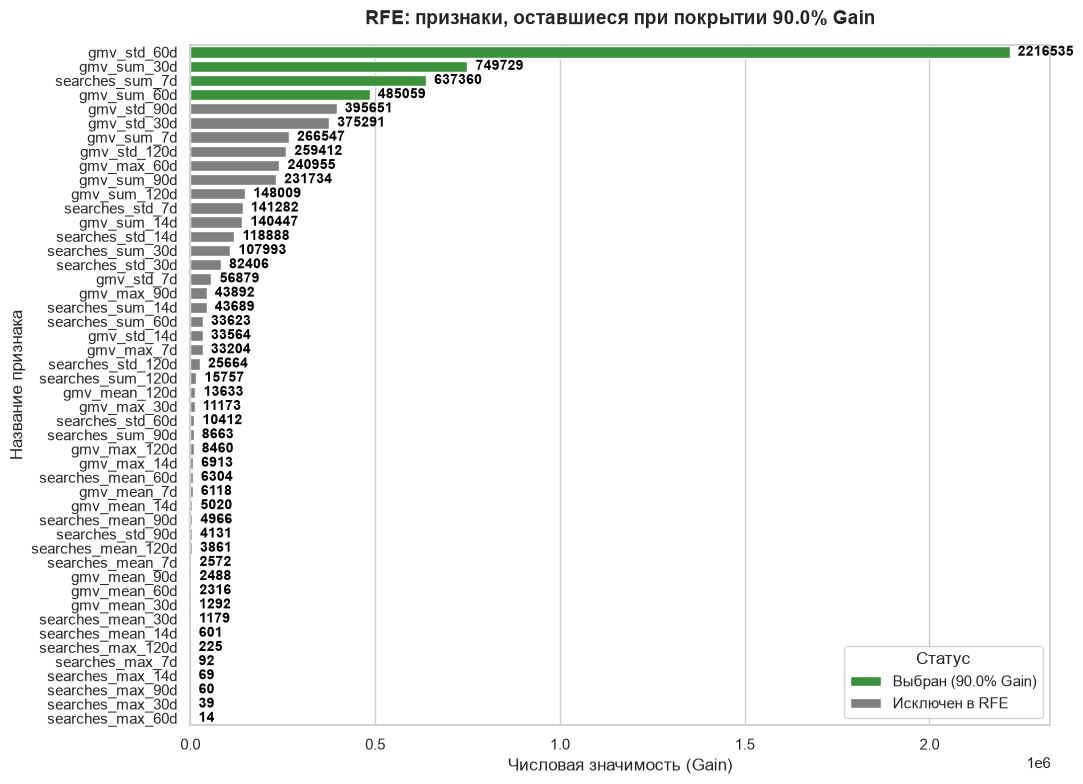

In [ ]:
TARGET_GAIN = 0.9
print(f"Запуск кастомного RFE до покрытия {TARGET_GAIN * 100} % Gain...")

feature_names = list(X_train.columns)
active_indices = list(range(len(feature_names)))

X_numpy = X_train.to_numpy().astype(np.float32, copy=False)
y_binary = (y_train.to_numpy().ravel() > 0).astype(np.int32)

del X_train, y_train, train_lazy


history_importance = {}
rfe_history = []

while len(active_indices) > 1:

    print(f"Обучение на {len(active_indices)} признаках...")

    X_subset = X_numpy[:, active_indices]

    model = LGBMClassifier(
        n_estimators=100,
        random_state=90,
        class_weight="balanced",
        n_jobs=-1,
        importance_type="gain",
    )

    model.fit(X_subset, y_binary)

    importances = model.feature_importances_

    # --------------------------------------------------------
    # Считаем долю Gain каждого активного признака
    # --------------------------------------------------------

    total_gain = importances.sum()

    if total_gain == 0:
        print("Общий Gain равен 0 — останавливаем RFE.")
        break

    gain_share = importances / total_gain

    # --------------------------------------------------------
    # Сколько признаков нужно для покрытия TARGET_GAIN % Gain
    # --------------------------------------------------------

    sorted_positions = np.argsort(gain_share)[::-1]

    sorted_gain = gain_share[sorted_positions]

    cumulative_gain = np.cumsum(sorted_gain)

    n_for_treshold = np.searchsorted(
        cumulative_gain,
        TARGET_GAIN,
        side="left"
    ) + 1

    # --------------------------------------------------------
    # Если ВСЕ активные признаки нужны для TARGET_GAIN %,
    # удалять больше нельзя
    # --------------------------------------------------------

    if n_for_treshold >= len(active_indices):

        print(
            f"Остановлено: для покрытия "
            f"{(TARGET_GAIN * 100):.0%} Gain нужны все "
            f"{len(active_indices)} оставшихся признаков."
        )

        # Сохраняем importance последней модели
        for pos, idx in enumerate(active_indices):
            history_importance[feature_names[idx]] = importances[pos]

        rfe_history.append({
            "n_features": len(active_indices),
            "n_for_85": n_for_treshold,
            "coverage_85": cumulative_gain[n_for_treshold - 1],
        })

        del X_subset, importances, model
        break

    # --------------------------------------------------------
    # Самый слабый признак удаляем
    # --------------------------------------------------------

    worst_pos = int(np.argmin(importances))
    worst_idx = active_indices[worst_pos]
    worst_feature = feature_names[worst_idx]

    # Сохраняем Gain на момент удаления
    history_importance[worst_feature] = importances[worst_pos]

    # --------------------------------------------------------
    # Сохраняем историю RFE
    # --------------------------------------------------------

    rfe_history.append({
        "n_features": len(active_indices),
        "n_for_treshold": n_for_treshold,
        "coverage_treshold": cumulative_gain[n_for_treshold - 1],
        "removed_feature": worst_feature,
        "removed_gain": importances[worst_pos],
    })

    print(
        f"Удаляем: {worst_feature} | "
        f"Gain={importances[worst_pos]:.2f} | "
        f"для 85% Gain нужно: {n_for_treshold}"
    )

    del active_indices[worst_pos]

    del X_subset, importances, model


# ============================================================
# Финальная модель на оставшихся признаках
# ============================================================

print()
print(
    f"Обучение финальной модели на "
    f"{len(active_indices)} признаках..."
)

X_subset = X_numpy[:, active_indices]

final_model = LGBMClassifier(
    n_estimators=100,
    random_state=90,
    class_weight="balanced",
    n_jobs=-1,
    importance_type="gain",
)

final_model.fit(X_subset, y_binary)

final_importances = final_model.feature_importances_

# Сохраняем финальный Gain
for idx, imp in zip(active_indices, final_importances):
    history_importance[feature_names[idx]] = imp


# ============================================================
# Финальный список признаков
# ============================================================

features_to_use = [
    feature_names[idx]
    for idx in active_indices
]

print()
print("=" * 60)
print("РЕЗУЛЬТАТ RFE")
print("=" * 60)
print(f"Исходное количество признаков: {len(feature_names)}")
print(f"Оставлено признаков:            {len(features_to_use)}")
print(f"Целевое покрытие Gain:          {(TARGET_GAIN * 100):.0%}")

print("\nВыбранные признаки:")
for i, feature in enumerate(features_to_use, 1):
    print(f"{i:2}. {feature}")


# ============================================================
# Таблица importance
# ============================================================

importance_df = pl.DataFrame({
    "Feature": list(history_importance.keys()),
    "Importance": list(history_importance.values()),
}).sort(
    "Importance",
    descending=True,
)

importance_df = importance_df.with_columns(
    pl.when(pl.col("Feature").is_in(features_to_use))
    .then(pl.lit(f"Выбран ({TARGET_GAIN * 100}% Gain)"))
    .otherwise(pl.lit("Исключен в RFE"))
    .alias("Color_Group")
)


# ============================================================
# История RFE
# ============================================================

rfe_history_df = pl.DataFrame(rfe_history)

print("\nПоследние шаги RFE:")
print(rfe_history_df.tail(10))


# ============================================================
# График
# ============================================================

sns.set_theme(style="whitegrid")

plt.figure(figsize=(11, 8), dpi=100)

ax = sns.barplot(
    x="Importance",
    y="Feature",
    hue="Color_Group",
    data=importance_df.to_pandas(),
    palette={
        f"Выбран ({(TARGET_GAIN * 100)}% Gain)": "#2ca02c",
        "Исключен в RFE": "#7f7f7f",
    },
    dodge=False,
)

for p in ax.patches:

    width = p.get_width()

    if width > 0:
        ax.text(
            width + max(importance_df["Importance"]) * 0.01,
            p.get_y() + p.get_height() / 2,
            f"{int(width)}",
            va="center",
            ha="left",
            color="black",
            fontweight="semibold",
            fontsize=10,
        )

plt.title(
    f"RFE: признаки, оставшиеся при покрытии {TARGET_GAIN * 100}% Gain",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

plt.xlabel(
    "Числовая значимость (Gain)",
    fontsize=12,
)

plt.ylabel(
    "Название признака",
    fontsize=12,
)

plt.legend(
    title="Статус",
    loc="lower right",
)

plt.tight_layout()
plt.show()


del X_subset
del X_numpy
del y_binary
del final_model
del final_importances
del active_indices
del feature_names

In [ ]:
features_to_use

['searches_sum_7d', 'gmv_sum_30d', 'gmv_sum_60d', 'gmv_std_60d']

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve

train_lazy = pl.scan_parquet(TRAIN_PATH)
X_train = train_lazy.select(features_to_use).collect()
y_train = train_lazy.select(target_col).collect()
y_train_binary = (y_train.to_numpy().ravel() > 0).astype(np.int32)

valid_lazy = pl.scan_parquet(VALID_PATH)
X_valid = valid_lazy.select(features_to_use).collect()
y_valid = valid_lazy.select(target_col).collect()
y_valid_binary = (y_valid.to_numpy().ravel() > 0).astype(np.int32)

# ============================================================
# 2. Обучаем финальную модель на ВСЕХ train данных
# ============================================================
final_model = LGBMClassifier(
    n_estimators=200,  # можно увеличить
    random_state=90,
    class_weight="balanced",
    n_jobs=-1,
    importance_type="gain",
)

final_model.fit(X_train.to_numpy().astype(np.float32), y_train_binary)


y_pred_proba = final_model.predict_proba(X_valid.to_numpy().astype(np.float32))[:, 1]
roc_auc = roc_auc_score(y_valid_binary, y_pred_proba)
print(f"ROC-AUC на валидации: {roc_auc:.4f}")

fpr, tpr, thresholds = roc_curve(y_valid_binary, y_pred_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.show()

from sklearn.metrics import precision_score, recall_score, f1_score

pred_proba_treshold = 0.5
y_pred_class = (y_pred_proba >= pred_proba_treshold).astype(int)

precision = precision_score(y_valid_binary, y_pred_class)
recall = recall_score(y_valid_binary, y_pred_class)
f1 = f1_score(y_valid_binary, y_pred_class)

print(f"\nДополнительные метрики (при пороге {pred_proba_treshold}:")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]
print(f"\nОптимальный порог (макс. J-статистики): {optimal_threshold:.4f}")

# Предсказания с оптимальным порогом
y_pred_optimal = (y_pred_proba >= optimal_threshold).astype(int)

precision_opt = precision_score(y_valid_binary, y_pred_optimal)
recall_opt = recall_score(y_valid_binary, y_pred_optimal)
f1_opt = f1_score(y_valid_binary, y_pred_optimal)

print(f"При оптимальном пороге:")
print(f"Precision: {precision_opt:.4f}")
print(f"Recall: {recall_opt:.4f}")
print(f"F1-score: {f1_opt:.4f}")

# ============================================================
# 8. Сохраняем модель для продакшена
# ============================================================
import joblib

# Сохраняем модель и список признаков
joblib.dump(final_model, "final_model.pkl")
joblib.dump(features_to_use, "selected_features.pkl")

print("\nМодель сохранена как 'final_model.pkl'")
print(f"Использовано признаков: {len(features_to_use)}")